In [33]:
#imports
import os
import io
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from scipy.stats import bootstrap

In [34]:
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")

Using compute device: cpu


In [13]:
# Configure output directories relative to the current notebook location
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "DATA"))
OUTPUT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "OUTPUT"))
os.makedirs(DATA_DIR, exist_ok=True)

# Seaborn & Matplotlib display settings
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.sans-serif": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11
})


In [14]:
def rgb_to_hex(rgb):
    """Convert an RGB array/tuple to a standard hex string."""
    return "#{:02x}{:02x}{:02x}".format(int(rgb[0]), int(rgb[1]), int(rgb[2]))

def extract_top_two_colors(image_url, session=None):
    """
    Downloads a sprite, filters out transparent pixels (alpha <= 50),
    and clusters non-background pixels using KMeans (k=2) to get the 
    top 2 dominant colors and their exact pixel percentages.
    """
    if not image_url:
        return None, 0.0, None, 0.0

    client = session or requests
    try:
        resp = client.get(image_url, timeout=10)
        resp.raise_for_status()
        
        img = Image.open(io.BytesIO(resp.content)).convert("RGBA")
        np_img = np.array(img)

        # Filter out alpha/transparent background
        visible_mask = np_img[:, :, 3] > 50
        visible_pixels = np_img[visible_mask][:, :3]  # Keep only RGB channels

        # Check for empty/corrupt sprites
        if len(visible_pixels) < 20:
            return None, 0.0, None, 0.0

        # Cluster visible pixels into 2 dominant color centers
        kmeans = KMeans(n_clusters=2, random_state=42, n_init="auto")
        labels = kmeans.fit_predict(visible_pixels)

        counts = np.bincount(labels, minlength=2)
        total_pixels = len(visible_pixels)

        # Sort descending by pixel volume
        sorted_indices = np.argsort(-counts)
        idx1, idx2 = sorted_indices[0], sorted_indices[1]

        c1_rgb = kmeans.cluster_centers_[idx1]
        c1_pct = float(counts[idx1] / total_pixels)

        c2_rgb = kmeans.cluster_centers_[idx2]
        c2_pct = float(counts[idx2] / total_pixels)

        return rgb_to_hex(c1_rgb), round(c1_pct, 4), rgb_to_hex(c2_rgb), round(c2_pct, 4)

    except Exception as e:
        return None, 0.0, None, 0.0

In [ ]:
# 1. Exact list of Pokémon species where male and female have distinctly different color palettes
COLOR_DIMORPHIC_SPECIES = {
    "unfezant",     # Male: green underside/pink wattle; Female: brown
    "frillish",     # Male: blue; Female: pink
    "jellicent",    # Male: blue; Female: pink
    "hippopotas",   # Male: light brown/yellow; Female: dark inverted brown
    "hippowdon",    # Male: light brown; Female: charcoal grey/black
    "pyroar",       # Male: massive red/yellow mane; Female: ponytail
    "meowstic",     # Male: dark blue dominant; Female: white dominant
    "indeedee",     # Male: dark navy/black torso; Female: white torso
    "wobbuffet",    # Female has lipstick markings (creates secondary color shift)
    "basculegion"   # Male: red accents; Female: cyan accents
}

print("Fetching complete index of all Pokémon forms from PokéAPI...")
forms_index = requests.get("https://pokeapi.co/api/v2/pokemon-form?limit=2000").json().get("results", [])
total_forms = len(forms_index)
print(f"Discovered {total_forms} forms. Beginning filtered extraction...")

normal_records = []
shiny_records = []
session = requests.Session()

# Tracking to keep only 1 Unown
unown_captured = False

for i, form_ref in enumerate(forms_index, 1):
    form_name = form_ref["name"]

    # RULE 1: Unown Filter (keep only the first one encountered, e.g., 'unown-a')
    if form_name.startswith("unown"):
        if unown_captured:
            continue
        unown_captured = True

    try:
        form_data = session.get(form_ref["url"], timeout=10).json()
        form_id = form_data.get("id")

        # Species linking for leak-free train/test splitting
        species_url = form_data.get("pokemon", {}).get("url")
        species_id = int(species_url.strip("/").split("/")[-1]) if species_url else form_id

        # Flags & Types
        is_mega = form_data.get("is_mega", False)
        is_battle_only = form_data.get("is_battle_only", False)
        types_list = sorted(form_data.get("types", []), key=lambda t: t.get("slot", 1))
        if not types_list:
            continue
        primary_type = types_list[0]["type"]["name"]
        secondary_type = types_list[1]["type"]["name"] if len(types_list) > 1 else None

        # Sprite endpoints (HOME renders preferred; standard front sprite fallback)
        sprites = form_data.get("sprites", {}) or {}
        home_sprites = (sprites.get("other", {}) or {}).get("home", {}) or {}

        normal_url = home_sprites.get("front_default") or sprites.get("front_default")
        shiny_url = home_sprites.get("front_shiny") or sprites.get("front_shiny")

        if not normal_url:
            continue

        # Color extraction: Normal
        n_c1, n_c1_pct, n_c2, n_c2_pct = extract_top_two_colors(normal_url, session=session)
        normal_records.append({
            "form_id": form_id,
            "species_id": species_id,
            "form_name": form_name,
            "gender": "default",
            "primary_type": primary_type,
            "secondary_type": secondary_type,
            "is_mega": is_mega,
            "is_battle_only": is_battle_only,
            "sprite_url": normal_url,
            "primary_color_hex": n_c1,
            "primary_color_pct": n_c1_pct,
            "secondary_color_hex": n_c2,
            "secondary_color_pct": n_c2_pct,
            "is_shiny": False
        })

        # Color extraction: Shiny
        if shiny_url:
            s_c1, s_c1_pct, s_c2, s_c2_pct = extract_top_two_colors(shiny_url, session=session)
            shiny_records.append({
                "form_id": form_id,
                "species_id": species_id,
                "form_name": form_name,
                "gender": "default",
                "primary_type": primary_type,
                "secondary_type": secondary_type,
                "is_mega": is_mega,
                "is_battle_only": is_battle_only,
                "sprite_url": shiny_url,
                "primary_color_hex": s_c1,
                "primary_color_pct": s_c1_pct,
                "secondary_color_hex": s_c2,
                "secondary_color_pct": s_c2_pct,
                "is_shiny": True
            })

        # RULE 2: Female Color Dimorphism
        # If this Pokémon species belongs to the color-dimorphic list, pull the female sprite
        base_name = form_name.split("-")[0].lower()
        if base_name in COLOR_DIMORPHIC_SPECIES:
            f_norm_url = home_sprites.get("front_female") or sprites.get("front_female")
            f_shiny_url = home_sprites.get("front_shiny_female") or sprites.get("front_shiny_female")

            if f_norm_url:
                fn_c1, fn_c1_pct, fn_c2, fn_c2_pct = extract_top_two_colors(f_norm_url, session=session)
                normal_records.append({
                    "form_id": form_id,
                    "species_id": species_id,
                    "form_name": f"{form_name}-female",
                    "gender": "female",
                    "primary_type": primary_type,
                    "secondary_type": secondary_type,
                    "is_mega": is_mega,
                    "is_battle_only": is_battle_only,
                    "sprite_url": f_norm_url,
                    "primary_color_hex": fn_c1,
                    "primary_color_pct": fn_c1_pct,
                    "secondary_color_hex": fn_c2,
                    "secondary_color_pct": fn_c2_pct,
                    "is_shiny": False
                })

            if f_shiny_url:
                fs_c1, fs_c1_pct, fs_c2, fs_c2_pct = extract_top_two_colors(f_shiny_url, session=session)
                shiny_records.append({
                    "form_id": form_id,
                    "species_id": species_id,
                    "form_name": f"{form_name}-female",
                    "gender": "female",
                    "primary_type": primary_type,
                    "secondary_type": secondary_type,
                    "is_mega": is_mega,
                    "is_battle_only": is_battle_only,
                    "sprite_url": f_shiny_url,
                    "primary_color_hex": fs_c1,
                    "primary_color_pct": fs_c1_pct,
                    "secondary_color_hex": fs_c2,
                    "secondary_color_pct": fs_c2_pct,
                    "is_shiny": True
                })

        if i % 100 == 0 or i == total_forms:
            print(f"Processed [{i}/{total_forms}] forms...")

    except Exception as err:
        print(f"Error processing form {form_ref.get('name', 'unknown')}: {err}")
        continue

df_normal = pd.DataFrame(normal_records)
df_shiny = pd.DataFrame(shiny_records)

# Save datasets to ../DATA
normal_csv_path = os.path.join(DATA_DIR, "pokemon_forms_normal.csv")
shiny_csv_path = os.path.join(DATA_DIR, "pokemon_forms_shiny.csv")

Fetching complete index of all Pokémon forms from PokéAPI...
Discovered 1579 forms. Beginning filtered extraction...
Processed [100/1579] forms...
Processed [200/1579] forms...
Processed [300/1579] forms...
Processed [400/1579] forms...
Processed [500/1579] forms...
Processed [600/1579] forms...
Processed [700/1579] forms...
Processed [800/1579] forms...
Processed [900/1579] forms...
Processed [1000/1579] forms...
Processed [1100/1579] forms...
Processed [1200/1579] forms...
Processed [1400/1579] forms...
Processed [1500/1579] forms...
Processed [1579/1579] forms...

Saved clean form datasets to:
1. c:\Users\crazy\DS-4002-group-01\project3\DATA\pokemon_forms_normal.csv (1514 records)
2. c:\Users\crazy\DS-4002-group-01\project3\DATA\pokemon_forms_shiny.csv (1514 records)


In [27]:
df_normal.to_csv(normal_csv_path, index=False)
df_shiny.to_csv(shiny_csv_path, index=False)

df_normal = df_normal[df_normal["form_name"] != "arceus-unknown"].reset_index(drop=True)
df_shiny = df_shiny[df_shiny["form_name"] != "arceus-unknown"].reset_index(drop=True)

print(df_normal.head)
df_shiny

<bound method NDFrame.head of       form_id  species_id             form_name   gender primary_type  \
0           1           1             bulbasaur  default        grass   
1           2           2               ivysaur  default        grass   
2           3           3              venusaur  default        grass   
3           4           4            charmander  default         fire   
4           5           5            charmeleon  default         fire   
...       ...         ...                   ...      ...          ...   
1508    10550       10325       baxcalibur-mega  default       dragon   
1509    10551         668         pyroar-female  default         fire   
1510    10552         592       frillish-female  default        water   
1511    10553         593      jellicent-female  default        water   
1512    10554       10326  meowstic-female-mega  default      psychic   

     secondary_type  is_mega  is_battle_only  \
0            poison    False           False 

,form_id,species_id,form_name,gender,primary_type,secondary_type,is_mega,is_battle_only,sprite_url,primary_color_hex,primary_color_pct,secondary_color_hex,secondary_color_pct,is_shiny
0,1,1,bulbasaur,default,grass,poison,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#b4e79c,0.5184,#7fb175,0.4816,True
1,2,2,ivysaur,default,grass,poison,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#c5d992,0.5416,#6e9e5e,0.4584,True
2,3,3,venusaur,default,grass,poison,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#88be72,0.6220,#dfd994,0.3780,True
3,4,4,charmander,default,fire,NaN,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#e8d376,0.8339,#cb7d25,0.1661,True
4,5,5,charmeleon,default,fire,NaN,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#dfb064,0.7689,#eae8ca,0.2311,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1508,10550,10325,baxcalibur-mega,default,dragon,ice,True,True,https://raw.githubusercontent.com/PokeAPI/spri...,#265962,0.5173,#a8c3d7,0.4827,True
1509,10551,668,pyroar-female,default,fire,normal,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#906447,0.7701,#fbe396,0.2299,True
1510,10552,592,frillish-female,default,water,ghost,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#e4acc0,0.7345,#432332,0.2655,True
1511,10553,593,jellicent-female,default,water,ghost,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#d4b7ee,0.7872,#332740,0.2128,True


In [28]:
# 1. Verify Unown only appears once
unown_count = len(df_normal[df_normal["form_name"].str.contains("unown")])
print(f"Unown entries: {unown_count} (Expected: 1)")

# 2. Check counts of Regional forms
alolan_count = len(df_normal[df_normal["form_name"].str.contains("-alola")])
galar_count = len(df_normal[df_normal["form_name"].str.contains("-galar")])
hisui_count = len(df_normal[df_normal["form_name"].str.contains("-hisui")])
paldea_count = len(df_normal[df_normal["form_name"].str.contains("-paldea")])
mega_count = len(df_normal[df_normal["is_mega"] == True])

print(f"Mega Evolutions: {mega_count}")
print(f"Regional Variants -> Alola: {alolan_count}, Galar: {galar_count}, Hisui: {hisui_count}, Paldea: {paldea_count}")

# 3. Check Female Dimorphism (e.g., Hippowdon or Meowstic)
female_dimorphs = df_normal[df_normal["gender"] == "female"][["form_name", "primary_type", "primary_color_hex"]]
print(f"\nColor-Dimorphic Female records ({len(female_dimorphs)} added):")
display(female_dimorphs)

Unown entries: 1 (Expected: 1)
Mega Evolutions: 97
Regional Variants -> Alola: 20, Galar: 20, Hisui: 16, Paldea: 4

Color-Dimorphic Female records (10 added):


,form_name,primary_type,primary_color_hex
202,wobbuffet-female,psychic,#04c1de
450,hippopotas-female,ground,#8b5930
452,hippowdon-female,ground,#6e6066
524,unfezant-female,normal,#6b635c
596,frillish-male-female,water,#f7cadc
598,jellicent-male-female,water,#e8d2dd
674,pyroar-male-female,fire,#d3b175
685,meowstic-male-female,psychic,#e8eaeb
884,indeedee-male-female,psychic,#cfcbda
911,basculegion-male-female,water,#caddd8


In [29]:
# Check normal head and verify nulls
print("Normal Data Sample:")
display(df_normal.head())

print("\nShiny Data Sample:")
display(df_shiny.head())

Normal Data Sample:


,form_id,species_id,form_name,gender,primary_type,secondary_type,is_mega,is_battle_only,sprite_url,primary_color_hex,primary_color_pct,secondary_color_hex,secondary_color_pct,is_shiny,primary_hue,color_category
0,1,1,bulbasaur,default,grass,poison,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#8ed1c3,0.6345,#589448,0.3655,False,167.462687,Green
1,2,2,ivysaur,default,grass,poison,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#5bb4c3,0.5619,#7c7142,0.4381,False,188.653846,Blue
2,3,3,venusaur,default,grass,poison,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#a38a58,0.6389,#03c4da,0.3611,False,40.000000,Orange
3,4,4,charmander,default,fire,NaN,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#e67a05,0.7245,#efdf89,0.2755,False,31.200000,Brown/Tan
4,5,5,charmeleon,default,fire,NaN,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#d73f25,0.7453,#e7d8a5,0.2547,False,8.764045,Brown/Tan



Shiny Data Sample:


,form_id,species_id,form_name,gender,primary_type,secondary_type,is_mega,is_battle_only,sprite_url,primary_color_hex,primary_color_pct,secondary_color_hex,secondary_color_pct,is_shiny
0,1,1,bulbasaur,default,grass,poison,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#b4e79c,0.5184,#7fb175,0.4816,True
1,2,2,ivysaur,default,grass,poison,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#c5d992,0.5416,#6e9e5e,0.4584,True
2,3,3,venusaur,default,grass,poison,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#88be72,0.6220,#dfd994,0.3780,True
3,4,4,charmander,default,fire,NaN,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#e8d376,0.8339,#cb7d25,0.1661,True
4,5,5,charmeleon,default,fire,NaN,False,False,https://raw.githubusercontent.com/PokeAPI/spri...,#dfb064,0.7689,#eae8ca,0.2311,True


C:\Users\crazy\AppData\Local\Temp\ipykernel_25120\1379884172.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x=type_counts.index, y=type_counts.values, palette=palette)


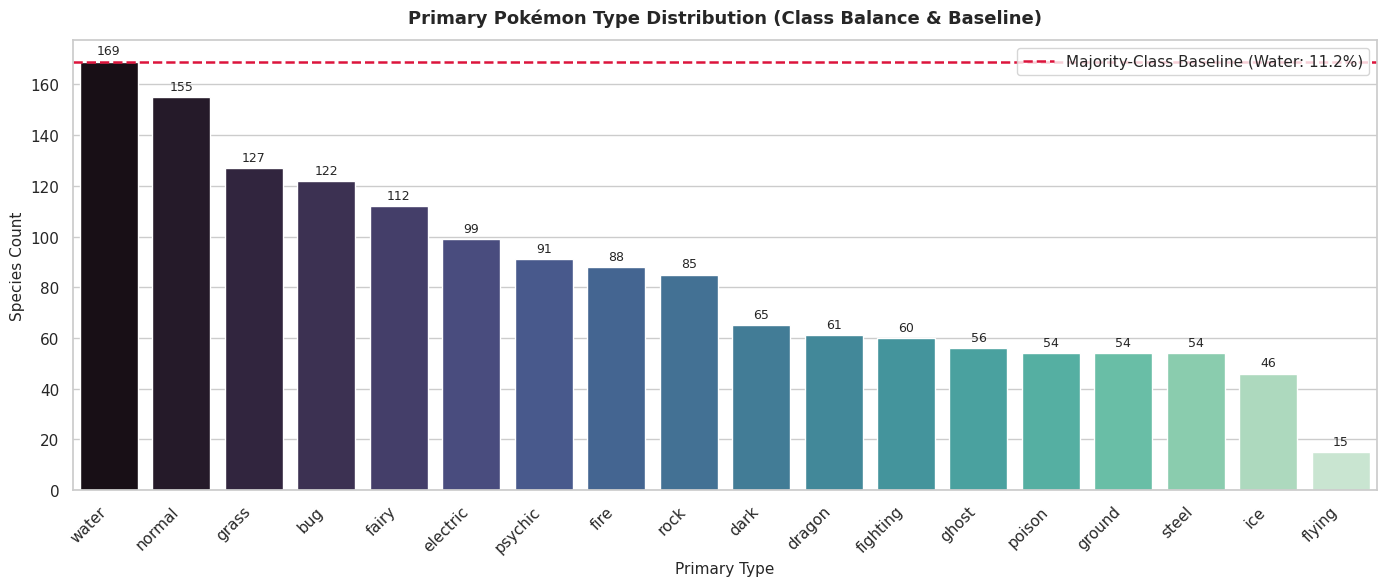

Saved plot to: c:\Users\crazy\DS-4002-group-01\project3\OUTPUT\plot1_type_distribution.png


In [30]:
plt.figure(figsize=(14, 6))

type_counts = df_normal["primary_type"].value_counts()
total_pokemon = len(df_normal)
majority_type = type_counts.index[0]
majority_pct = (type_counts.iloc[0] / total_pokemon) * 100

palette = sns.color_palette("mako", len(type_counts))
ax1 = sns.barplot(x=type_counts.index, y=type_counts.values, palette=palette)

# Benchmark line for majority-class guessing
plt.axhline(
    y=type_counts.iloc[0],
    color="crimson",
    linestyle="--",
    linewidth=1.8,
    label=f"Majority-Class Baseline ({majority_type.capitalize()}: {majority_pct:.1f}%)"
)

plt.title("Primary Pokémon Type Distribution (Class Balance & Baseline)", weight="bold", pad=12)
plt.xlabel("Primary Type")
plt.ylabel("Species Count")
plt.xticks(rotation=45, ha="right")
plt.legend(frameon=True, loc="upper right")

for p in ax1.patches:
    val = int(p.get_height())
    if val > 0:
        ax1.annotate(f"{val}", (p.get_x() + p.get_width() / 2.0, val),
                     ha="center", va="bottom", fontsize=9, xytext=(0, 3),
                     textcoords="offset points")

plt.tight_layout()
plot1_path = os.path.join(OUTPUT_DIR, "plot1_type_distribution.png")
plt.savefig(plot1_path, dpi=300)
plt.show()
print(f"Saved plot to: {plot1_path}")

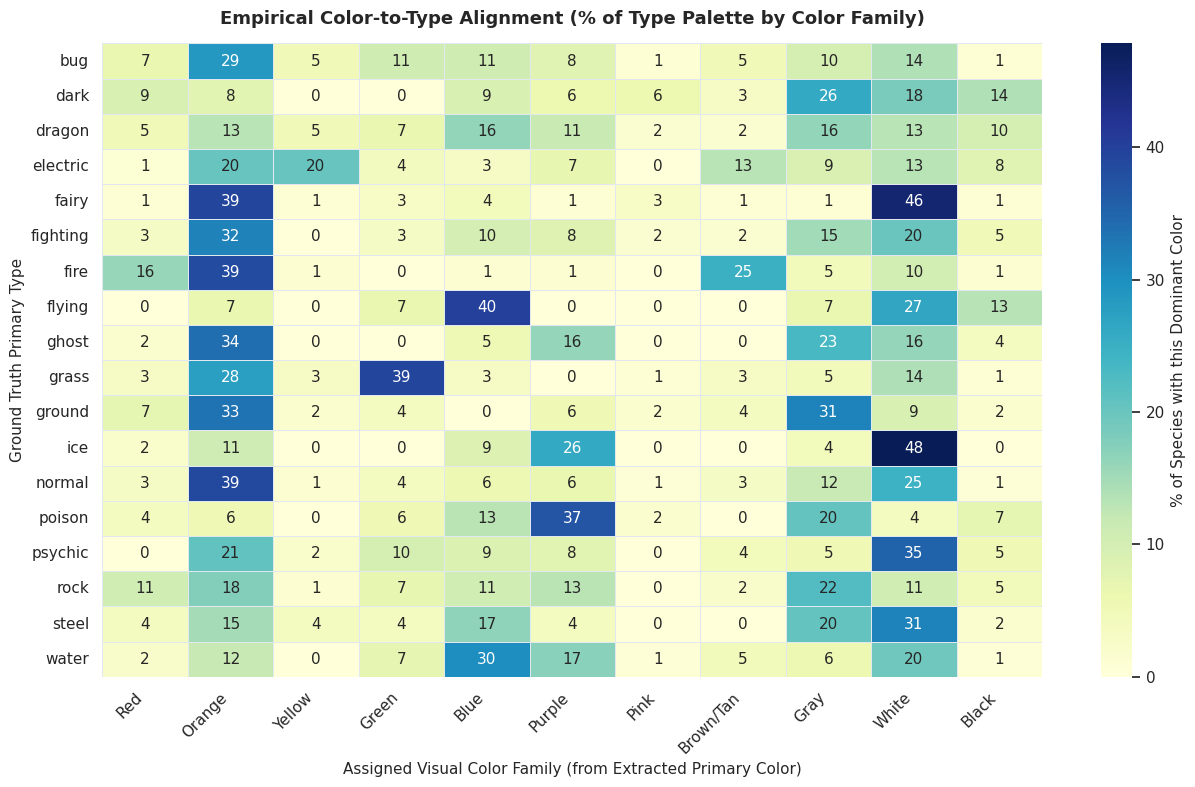

Saved color-to-type alignment heatmap to: c:\Users\crazy\DS-4002-group-01\project3\OUTPUT\plot2_color_type_alignment_heatmap.png


In [32]:
def classify_color_name(hex_str):
    """
    Maps an RGB hex string to an intuitive visual color family
    using normalized RGB channel comparisons and brightness thresholds.
    """
    if not isinstance(hex_str, str) or not hex_str.startswith("#"):
        return "Unknown"
    
    r = int(hex_str[1:3], 16) / 255.0
    g = int(hex_str[3:5], 16) / 255.0
    b = int(hex_str[5:7], 16) / 255.0
    
    max_c = max(r, g, b)
    min_c = min(r, g, b)
    chroma = max_c - min_c
    brightness = 0.299 * r + 0.587 * g + 0.114 * b

    # Low-saturation / grayscale categories
    if chroma < 0.15:
        if brightness > 0.75:
            return "White"
        elif brightness < 0.25:
            return "Black"
        else:
            return "Gray"

    # Chromatic categories based on channel dominance
    if r > 0.4 and g > 0.2 and b < 0.2 and (r - g) > 0.15:
        return "Brown/Tan"
    if r > g and r > b:
        if g > 0.6 and b < 0.3:
            return "Yellow"
        elif g > 0.35:
            return "Orange"
        elif b > 0.35:
            return "Pink"
        return "Red"
    elif g > r and g > b:
        return "Green"
    elif b > r and b > g:
        if r > 0.4:
            return "Purple"
        return "Blue"
    elif r > 0.5 and b > 0.5 and g < 0.4:
        return "Purple"
    
    return "Other"

# Apply mapping to dominant color
df_normal["color_category"] = df_normal["primary_color_hex"].apply(classify_color_name)

# Cross-tabulate and normalize by type row to show percentage distribution
ct = pd.crosstab(df_normal["primary_type"], df_normal["color_category"], normalize="index") * 100

# Order columns cleanly from chromatic to neutral
col_order = ["Red", "Orange", "Yellow", "Green", "Blue", "Purple", "Pink", "Brown/Tan", "Gray", "White", "Black"]
present_cols = [c for c in col_order if c in ct.columns]
ct = ct[present_cols]

# Plot heatmap
plt.figure(figsize=(13, 8))
sns.heatmap(
    ct,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    cbar_kws={"label": "% of Species with this Dominant Color"},
    linewidths=0.5,
    linecolor="#e2e8f0"
)

plt.title("Empirical Color-to-Type Alignment (% of Type Palette by Color Family)", weight="bold", pad=14)
plt.xlabel("Assigned Visual Color Family (from Extracted Primary Color)", fontsize=11)
plt.ylabel("Ground Truth Primary Type", fontsize=11)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

# Save figure to ../DATA
plot2_path = os.path.join(OUTPUT_DIR, "plot2_color_type_alignment_heatmap.png")
plt.savefig(plot2_path, dpi=300)
plt.show()

print(f"Saved color-to-type alignment heatmap to: {plot2_path}")

In [35]:
# 1. Establish the 18 canonical primary types and integer label mappings
CANONICAL_TYPES = sorted([
    "normal", "fire", "water", "grass", "electric", "ice",
    "fighting", "poison", "ground", "flying", "psychic", "bug",
    "rock", "ghost", "dragon", "steel", "dark", "fairy"
])
type_to_idx = {t: i for i, t in enumerate(CANONICAL_TYPES)}
idx_to_type = {i: t for i, t in enumerate(CANONICAL_TYPES)}

# 2. Filter to canonical types
df_norm = df_normal[df_normal["primary_type"].isin(CANONICAL_TYPES)].copy()
df_shin = df_shiny[df_shiny["primary_type"].isin(CANONICAL_TYPES)].copy()

df_norm["label"] = df_norm["primary_type"].map(type_to_idx)
df_shin["label"] = df_shin["primary_type"].map(type_to_idx)

# 3. Reserve all Arceus forms for the Shape-vs-Color Ablation Test
is_arceus_norm = df_norm["form_name"].str.startswith("arceus")
is_arceus_shin = df_shin["form_name"].str.startswith("arceus")

df_arceus_test = df_norm[is_arceus_norm].copy().reset_index(drop=True)

# Dataset without Arceus for standard train/test splitting
df_pool_norm = df_norm[~is_arceus_norm].copy().reset_index(drop=True)
df_pool_shin = df_shin[~is_arceus_shin].copy().reset_index(drop=True)

# 4. Species-Grouped Split (80% Train, 20% Held-Out Test on species_id)
# Ensures all forms of a species stay on one side to prevent memorization leakage
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
train_idx, test_idx = next(gss.split(df_pool_norm, groups=df_pool_norm["species_id"]))

train_df = df_pool_norm.iloc[train_idx].copy().reset_index(drop=True)
test_normal_df = df_pool_norm.iloc[test_idx].copy().reset_index(drop=True)

# Shiny test set: strictly the identical species that were held out
held_out_species = set(test_normal_df["species_id"].unique())
test_shiny_df = df_pool_shin[df_pool_shin["species_id"].isin(held_out_species)].copy().reset_index(drop=True)

print(f"Dataset Partitions:")
print(f"  • Training (Normal forms only):        {len(train_df)} images ({train_df['species_id'].nunique()} species)")
print(f"  • Held-Out Test (Normal variants):     {len(test_normal_df)} images ({test_normal_df['species_id'].nunique()} species)")
print(f"  • Held-Out Test (Shiny variants):      {len(test_shiny_df)} images ({test_shiny_df['species_id'].nunique()} species)")
print(f"  • Arceus Ablation Test (Fixed Shape):  {len(df_arceus_test)} forms ({df_arceus_test['primary_type'].nunique()} types)")

Dataset Partitions:
  • Training (Normal forms only):        1198 images (1073 species)
  • Held-Out Test (Normal variants):     297 images (269 species)
  • Held-Out Test (Shiny variants):      297 images (269 species)
  • Arceus Ablation Test (Fixed Shape):  18 forms (18 types)


In [36]:
# Local sprite cache directory to avoid repeated web downloads during training epochs
SPRITE_CACHE_DIR = os.path.join(DATA_DIR, "sprite_cache")
os.makedirs(SPRITE_CACHE_DIR, exist_ok=True)

def get_image(url):
    """Fetches image, caches locally as PNG, and strips alpha channel to pure RGB on white background."""
    if not url or not isinstance(url, str):
        return Image.new("RGB", (224, 224), (255, 255, 255))
        
    filename = url.split("/")[-1]
    local_path = os.path.join(SPRITE_CACHE_DIR, filename)

    if os.path.exists(local_path):
        img = Image.open(local_path)
    else:
        resp = requests.get(url, timeout=10)
        img = Image.open(io.BytesIO(resp.content))
        img.save(local_path)

    # Convert transparent PNG background to clean white RGB
    if img.mode in ("RGBA", "LA"):
        canvas = Image.new("RGB", img.size, (255, 255, 255))
        canvas.paste(img, mask=img.split()[-1])
        return canvas
    return img.convert("RGB")


class PokemonSpriteDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform
        self.urls = df["sprite_url"].tolist()
        self.labels = df["label"].tolist()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img = get_image(self.urls[idx])
        label = self.labels[idx]

        if self.transform:
            img = self.transform(img)

        return img, label, self.df.iloc[idx]["form_name"]


# Preprocessing transforms (ImageNet mean & std normalization)
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Build PyTorch DataLoaders
train_loader = DataLoader(PokemonSpriteDataset(train_df, transform=train_transforms), batch_size=32, shuffle=True)
test_norm_loader = DataLoader(PokemonSpriteDataset(test_normal_df, transform=eval_transforms), batch_size=32, shuffle=False)
test_shin_loader = DataLoader(PokemonSpriteDataset(test_shiny_df, transform=eval_transforms), batch_size=32, shuffle=False)
arceus_loader = DataLoader(PokemonSpriteDataset(df_arceus_test, transform=eval_transforms), batch_size=32, shuffle=False)

In [37]:
def extract_color_histogram(url, bins_per_channel=8):
    """
    Computes a flattened, normalized 3D color histogram (8x8x8 = 512 features)
    strictly from visible pixels (alpha > 50).
    """
    img = get_image(url)
    np_img = np.array(img)
    # Exclude near-white background pixels (R, G, B > 245)
    mask = ~((np_img[:, :, 0] > 245) & (np_img[:, :, 1] > 245) & (np_img[:, :, 2] > 245))
    pixels = np_img[mask]
    
    if len(pixels) < 20:
        return np.zeros(bins_per_channel ** 3)
        
    hist, _ = np.histogramdd(
        pixels,
        bins=(bins_per_channel, bins_per_channel, bins_per_channel),
        range=[(0, 256), (0, 256), (0, 256)]
    )
    hist = hist.flatten()
    hist_norm = hist / (hist.sum() + 1e-7)
    return hist_norm

print("Extracting color histograms for baseline...")
X_train_hist = np.array([extract_color_histogram(u) for u in train_df["sprite_url"]])
y_train_hist = train_df["label"].values

X_test_norm_hist = np.array([extract_color_histogram(u) for u in test_normal_df["sprite_url"]])
y_test_norm_hist = test_normal_df["label"].values

X_test_shin_hist = np.array([extract_color_histogram(u) for u in test_shiny_df["sprite_url"]])
y_test_shin_hist = test_shiny_df["label"].values

# Fit Multiclass Logistic Regression
baseline_clf = LogisticRegression(max_iter=1000, C=1.0, random_state=SEED)
baseline_clf.fit(X_train_hist, y_train_hist)

acc_base_norm = accuracy_score(y_test_norm_hist, baseline_clf.predict(X_test_norm_hist))
acc_base_shin = accuracy_score(y_test_shin_hist, baseline_clf.predict(X_test_shin_hist))

print(f"\n--- Baseline Model (Color-Only Histogram Logistic Regression) ---")
print(f"Held-Out Normal Accuracy: {acc_base_norm * 100:.2f}%")
print(f"Held-Out Shiny Accuracy:  {acc_base_shin * 100:.2f}%")
print(f"Performance Drop on Shiny: {(acc_base_norm - acc_base_shin) * 100:.2f}%")

Extracting color histograms for baseline...

--- Baseline Model (Color-Only Histogram Logistic Regression) ---
Held-Out Normal Accuracy: 18.86%
Held-Out Shiny Accuracy:  18.86%
Performance Drop on Shiny: 0.00%


In [38]:
# Initialize pretrained ResNet-18
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# Replace 1000-class ImageNet output head with an 18-class linear layer
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, 18)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-3)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=12)

NUM_EPOCHS = 12
train_losses = []

print("Fine-tuning ResNet-18 on normal Pokémon sprites...")
for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for imgs, labels, _ in train_loader:
        imgs = imgs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imgs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

    scheduler.step()
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    train_losses.append(epoch_loss)

    print(f"Epoch [{epoch:02d}/{NUM_EPOCHS:02d}] - Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc * 100:.2f}%")

# Save model checkpoint to ../DATA
model_weights_path = os.path.join(DATA_DIR, "resnet18_pokemon_type.pth")
torch.save(model.state_dict(), model_weights_path)
print(f"\nModel weights saved to: {model_weights_path}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\crazy/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Fine-tuning ResNet-18 on normal Pokémon sprites...
Epoch [01/12] - Loss: 2.4677 | Train Acc: 26.21%
Epoch [02/12] - Loss: 1.6862 | Train Acc: 51.25%
Epoch [03/12] - Loss: 1.2202 | Train Acc: 68.36%
Epoch [04/12] - Loss: 0.8803 | Train Acc: 79.72%
Epoch [05/12] - Loss: 0.5890 | Train Acc: 90.40%
Epoch [06/12] - Loss: 0.4369 | Train Acc: 94.41%
Epoch [07/12] - Loss: 0.3241 | Train Acc: 96.24%
Epoch [08/12] - Loss: 0.2455 | Train Acc: 97.91%
Epoch [09/12] - Loss: 0.2047 | Train Acc: 98.41%
Epoch [10/12] - Loss: 0.1957 | Train Acc: 98.75%
Epoch [11/12] - Loss: 0.1738 | Train Acc: 99.00%
Epoch [12/12] - Loss: 0.1621 | Train Acc: 99.25%

Model weights saved to: c:\Users\crazy\DS-4002-group-01\project3\OUTPUT\resnet18_pokemon_type.pth


In [ ]:
def evaluate_model(model, dataloader):
    """Runs inference and extracts accuracy, true labels, predicted labels, and correctness flags."""
    model.eval()
    all_preds = []
    all_labels = []
    all_names = []

    with torch.no_grad():
        for imgs, labels, names in dataloader:
            imgs = imgs.to(device)
            outputs = model(imgs)
            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_names.extend(names)

    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    correct_mask = (all_preds == all_labels).astype(int)
    acc = np.mean(correct_mask)

    return acc, all_labels, all_preds, correct_mask, all_names

# Evaluate partitions
acc_norm, y_true_norm, y_pred_norm, mask_norm, names_norm = evaluate_model(model, test_norm_loader)
acc_shin, y_true_shin, y_pred_shin, mask_shin, names_shin = evaluate_model(model, test_shin_loader)
acc_arc, y_true_arc, y_pred_arc, mask_arc, names_arc = evaluate_model(model, arceus_loader)

print("=" * 55)
print("           RESNET-18 EVALUATION RESULTS")
print("=" * 55)
print(f"Held-Out Normal Species Accuracy: {acc_norm * 100:.2f}%")
print(f"Held-Out Shiny Species Accuracy:  {acc_shin * 100:.2f}%")
print(f"Raw Accuracy Delta (Normal - Shiny): {(acc_norm - acc_shin) * 100:.2f}%")
print(f"Arceus 18-Forms Accuracy:         {acc_arc * 100:.2f}%")
print("=" * 55)

In [ ]:
def compute_paired_accuracy_drop(indices):
    """
    Computes accuracy on normal minus shiny across matching species.
    Uses aligned boolean vectors for valid paired bootstrapping.
    """
    # Sample with replacement across test species indices
    sample_norm = mask_norm[indices]
    sample_shin = mask_shin[indices]
    return np.mean(sample_norm) - np.mean(sample_shin)

# Number of bootstrap resamples
B = 2000
n_samples = min(len(mask_norm), len(mask_shin))
boot_deltas = []

for _ in range(B):
    boot_idx = np.random.choice(n_samples, size=n_samples, replace=True)
    delta = np.mean(mask_norm[boot_idx]) - np.mean(mask_shin[boot_idx])
    boot_deltas.append(delta)

boot_deltas = np.array(boot_deltas)

# 95% Percentile Bootstrap Interval
ci_lower = np.percentile(boot_deltas, 2.5) * 100
ci_upper = np.percentile(boot_deltas, 97.5) * 100
mean_delta = np.mean(boot_deltas) * 100

print(f"\n--- Bootstrap Statistical Significance (95% CI) ---")
print(f"Observed Accuracy Drop:      {(acc_norm - acc_shin) * 100:.2f}%")
print(f"95% Bootstrap CI for Drop:   [{ci_lower:.2f}%, {ci_upper:.2f}%]")

# Success Criteria Check against your proposal goal (Target: >= 30%)
target_met = acc_norm >= 0.30
print(f"\nGoal Verification (>= 30% held-out species accuracy): {'PASSED' if target_met else 'FAILED'}")
if ci_lower > 0:
    print("Statistical Conclusion: The accuracy drop on Shiny forms is statistically significant at p < 0.05.")
else:
    print("Statistical Conclusion: The drop is not statistically distinguishable from 0 at the 95% confidence level.")

In [ ]:
# Summary comparison bar plot
results_df = pd.DataFrame({
    "Condition": [
        "Majority Baseline",
        "Color Hist Logistic Reg (Normal)",
        "Color Hist Logistic Reg (Shiny)",
        "ResNet-18 (Held-out Normal)",
        "ResNet-18 (Held-out Shiny)",
        "ResNet-18 (Arceus Fixed-Shape)"
    ],
    "Accuracy (%)": [
        (df_pool_norm["primary_type"].value_counts().iloc[0] / len(df_pool_norm)) * 100,
        acc_base_norm * 100,
        acc_base_shin * 100,
        acc_norm * 100,
        acc_shin * 100,
        acc_arc * 100
    ],
    "Model Family": [
        "Baseline", "Logistic Regression", "Logistic Regression",
        "CNN (ResNet-18)", "CNN (ResNet-18)", "CNN (ResNet-18)"
    ]
})

plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=results_df,
    x="Condition",
    y="Accuracy (%)",
    hue="Model Family",
    palette={"Baseline": "#94a3b8", "Logistic Regression": "#38bdf8", "CNN (ResNet-18)": "#6366f1"}
)

# Benchmark line for success statement (30%)
plt.axhline(30.0, color="crimson", linestyle="--", linewidth=1.5, label="Project Target (30.0%)")
plt.title("Primary Type Prediction: Color Shortcut Evaluation", weight="bold", pad=12)
plt.xlabel("Evaluation Condition")
plt.ylabel("Classification Accuracy (%)")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)
plt.legend(frameon=True, loc="upper right")

for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(f"{val:.1f}%", (p.get_x() + p.get_width() / 2.0, val),
                     ha="center", va="bottom", fontsize=10, xytext=(0, 3),
                     textcoords="offset points")

plt.tight_layout()
eval_plot_path = os.path.join(OUTPUT_DIR, "model_comparison_benchmark.png")
plt.savefig(eval_plot_path, dpi=300)
plt.show()

print(f"Evaluation benchmark figure saved to: {eval_plot_path}")